In [11]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/anirudhchauhan/retail-store-inventory-forecasting-dataset/retail_store_inventory.csv


In [12]:
# IMPORT THE DATASET
data=pd.read_csv("/kaggle/input/datasets/anirudhchauhan/retail-store-inventory-forecasting-dataset/retail_store_inventory.csv")
data

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73095,2024-01-01,S005,P0016,Furniture,East,96,8,127,18.46,73.73,20,Snowy,0,72.45,Winter
73096,2024-01-01,S005,P0017,Toys,North,313,51,101,48.43,82.57,10,Cloudy,0,83.78,Autumn
73097,2024-01-01,S005,P0018,Clothing,West,278,36,151,39.65,11.11,10,Rainy,0,10.91,Winter
73098,2024-01-01,S005,P0019,Toys,East,374,264,21,270.52,53.14,20,Rainy,0,55.80,Spring


In [13]:
# COPY THE DATASET
df=data.copy()
df

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73095,2024-01-01,S005,P0016,Furniture,East,96,8,127,18.46,73.73,20,Snowy,0,72.45,Winter
73096,2024-01-01,S005,P0017,Toys,North,313,51,101,48.43,82.57,10,Cloudy,0,83.78,Autumn
73097,2024-01-01,S005,P0018,Clothing,West,278,36,151,39.65,11.11,10,Rainy,0,10.91,Winter
73098,2024-01-01,S005,P0019,Toys,East,374,264,21,270.52,53.14,20,Rainy,0,55.80,Spring


In [14]:
# CHECK NULL VALUE
df.isnull().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64

In [15]:
import os
import warnings
import logging

# Suppress environment and library logs before importing heavy modules
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('prophet').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

tf.get_logger().setLevel('ERROR')

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# DATA SYNTHESIS
print("Generating Synthetic Retail Sales Data")

date_range = pd.date_range(start="2023-01-01", end="2025-12-31", freq="D")
n_days = len(date_range)

# Trend, Seasonality, and External Events
baseline_demand = 100
trend = np.linspace(0, 50, n_days)
yearly_seasonality = 30 * np.sin(2 * np.pi * date_range.dayofyear / 365.25)
weekly_seasonality = 15 * (date_range.dayofweek >= 5)

is_promo = np.random.binomial(1, 0.15, n_days)
promo_impact = is_promo * np.random.normal(35, 5, n_days)

is_holiday = np.zeros(n_days)
holiday_indices = np.random.choice(n_days, size=15, replace=False)
is_holiday[holiday_indices] = 1
holiday_impact = is_holiday * np.random.normal(60, 10, n_days)

noise = np.random.normal(0, 10, n_days)

# Total Sales
sales = baseline_demand + trend + yearly_seasonality + weekly_seasonality + promo_impact + holiday_impact + noise
sales = np.maximum(sales, 0)

# Create DataFrame with explicit frequency to resolve statsmodels frequency warnings
df = pd.DataFrame({
    'date': date_range,
    'sales': np.round(sales, 2),
    'is_promo': is_promo,
    'is_holiday': is_holiday.astype(int)
}).set_index('date')
df.index.freq = 'D'

# Train/Test Split 
TEST_DAYS = 90
train_df = df.iloc[:-TEST_DAYS]
test_df = df.iloc[-TEST_DAYS:]

print(f"Data ready. Training samples: {len(train_df)}, Testing samples: {len(test_df)}\n")

# EVALUATION METRICS

def compute_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def compute_mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def evaluate_model(y_true, y_pred, model_name):
    rmse = compute_rmse(y_true, y_pred)
    mape = compute_mape(y_true, y_pred)
    print(f"[{model_name}] RMSE: {rmse:.2f} | MAPE: {mape:.2f}%")
    return rmse, mape

#  SARIMAX (With Exogenous Variables)

print("\n Training SARIMAX Model")
sarima_model = SARIMAX(
    train_df['sales'],
    exog=train_df[['is_promo', 'is_holiday']],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=500)

sarima_pred = sarima_model.predict(
    start=test_df.index[0], 
    end=test_df.index[-1],
    exog=test_df[['is_promo', 'is_holiday']]
)
rmse_arima, mape_arima = evaluate_model(test_df['sales'], sarima_pred, "SARIMAX")

# PROPHET

print("\n Training Prophet Model")
prophet_train = train_df.reset_index().rename(columns={'date': 'ds', 'sales': 'y'})
prophet_test = test_df.reset_index().rename(columns={'date': 'ds', 'sales': 'y'})

model_prophet = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
model_prophet.add_regressor('is_promo')
model_prophet.add_regressor('is_holiday')
model_prophet.fit(prophet_train)

future = prophet_test[['ds', 'is_promo', 'is_holiday']]
prophet_forecast = model_prophet.predict(future)
prophet_pred = prophet_forecast['yhat'].values

rmse_prophet, mape_prophet = evaluate_model(test_df['sales'], prophet_pred, "Prophet")

#LSTM (Leakage Free & Clean Execution)

print("\n Training LSTM Model")

# Fit scaler strictly on training data
scaler = MinMaxScaler()
scaled_train = scaler.fit_transform(train_df[['sales', 'is_promo', 'is_holiday']])

# Scale test data incorporating last LOOKBACK window from training set
LOOKBACK = 30
full_df = pd.concat([train_df.iloc[-LOOKBACK:], test_df])
scaled_full = scaler.transform(full_df[['sales', 'is_promo', 'is_holiday']])

def create_sequences(data, lookback):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, :])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(scaled_train, LOOKBACK)
X_test, _ = create_sequences(scaled_full, LOOKBACK)

# Model initialization using Input layer
lstm_model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mean_squared_error')
lstm_model.fit(X_train, y_train, epochs=20, batch_size=32, verbose=0)

# Perform inference directly to avoid tf.function retracing warnings
lstm_scaled_preds = lstm_model(X_test, training=False).numpy()

# Inverse transform predictions
dummy_matrix = np.zeros((len(lstm_scaled_preds), 3))
dummy_matrix[:, 0] = lstm_scaled_preds.flatten()
lstm_pred = scaler.inverse_transform(dummy_matrix)[:, 0]

rmse_lstm, mape_lstm = evaluate_model(test_df['sales'], lstm_pred, "LSTM")

#  RESULTS COMPARISON & PLOTTING

results_summary = pd.DataFrame({
    'Model': ['SARIMAX', 'Prophet', 'LSTM'],
    'RMSE': [rmse_arima, rmse_prophet, rmse_lstm],
    'MAPE (%)': [mape_arima, mape_prophet, mape_lstm]
}).sort_values(by='MAPE (%)')

print(results_summary.to_string(index=False))



Generating Synthetic Retail Sales Data
Data ready. Training samples: 1006, Testing samples: 90


 Training SARIMAX Model
[SARIMAX] RMSE: 21.90 | MAPE: 11.90%

 Training Prophet Model
[Prophet] RMSE: 10.82 | MAPE: 6.04%

 Training LSTM Model
[LSTM] RMSE: 27.14 | MAPE: 12.28%
  Model      RMSE  MAPE (%)
Prophet 10.816545  6.035333
SARIMAX 21.899750 11.903039
   LSTM 27.136810 12.279902


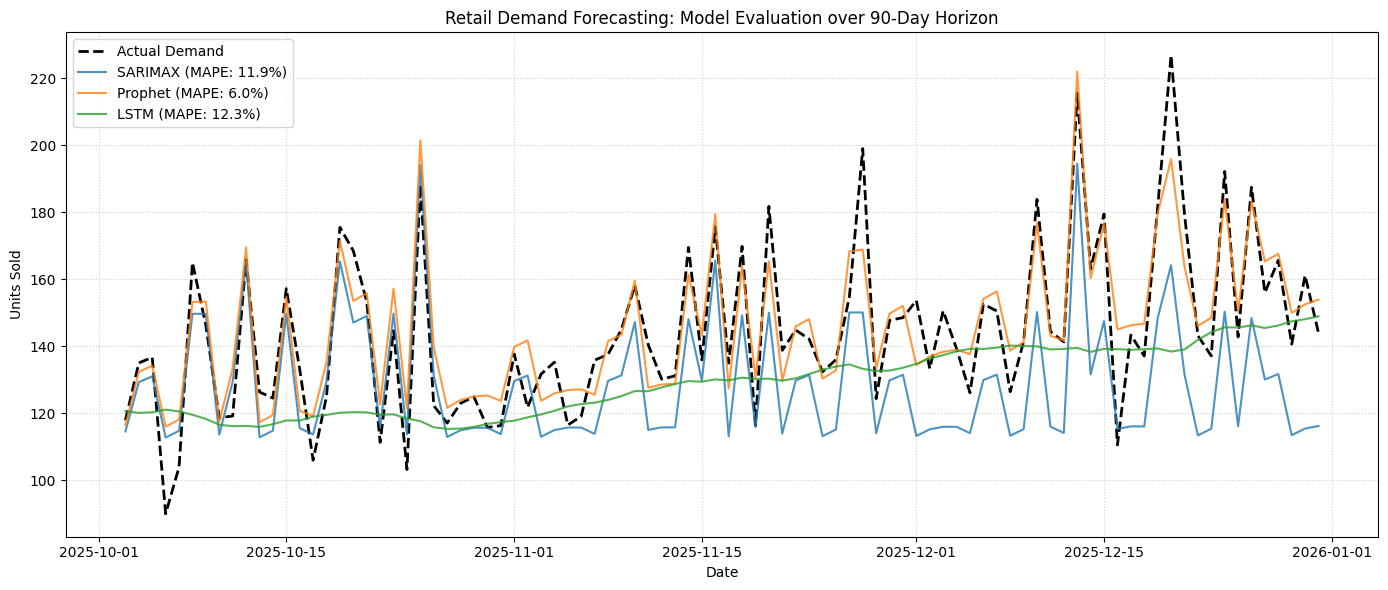

In [16]:
# Plot Output
plt.figure(figsize=(14, 6))
plt.plot(test_df.index, test_df['sales'], label='Actual Demand', color='black', linewidth=2, linestyle='--')
plt.plot(test_df.index, sarima_pred, label=f'SARIMAX (MAPE: {mape_arima:.1f}%)', alpha=0.8)
plt.plot(test_df.index, prophet_pred, label=f'Prophet (MAPE: {mape_prophet:.1f}%)', alpha=0.8)
plt.plot(test_df.index, lstm_pred, label=f'LSTM (MAPE: {mape_lstm:.1f}%)', alpha=0.8)

plt.title('Retail Demand Forecasting: Model Evaluation over 90-Day Horizon')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()